<a href="https://colab.research.google.com/github/silmucci/Artificial-Intelligence-From-Engineering-To-Arts/blob/main/Music_Emotion_Classification_and_Art_Generation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Music Emotion to Visual Art — Abstract and Figurative Generation

Questo notebook realizza una pipeline di **Machine Learning e AI generativa** per trasformare le emozioni musicali in immagini astratte e figurative.

Il progetto utilizza il **4Q Audio Emotion Dataset**, organizzato nei quattro quadranti del modello Valence-Arousal di Russell.

### Pipeline

**Audio → Estrazione delle feature → Classificazione dell'emozione → Prompt → Stable Diffusion → Immagine → Valutazione CLIP**

### Classi emotive

- **Q1 → Happy:** valenza positiva, arousal alto
- **Q2 → Tense:** valenza negativa, arousal alto
- **Q3 → Sad:** valenza negativa, arousal basso
- **Q4 → Calm:** valenza positiva, arousal basso

### Modelli confrontati

- Random Forest
- Extra Trees
- SVM con kernel RBF
- Logistic Regression

Il modello migliore viene selezionato in base al **Macro F1 medio in cross-validation sul training set**. Il test set viene utilizzato esclusivamente per la valutazione finale.

Le immagini vengono generate in modalità **astratta o figurativa** e valutate tramite **CLIP**, per analizzare la coerenza semantica con l'emozione predetta.

### Output

Tutti i risultati vengono salvati in:

`/content/drive/MyDrive/music_emotion_art_4q_project`

In [1]:
# 1) Mount di Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# 2) Installazione delle librerie
!pip install -q kagglehub
!pip install -q librosa soundfile numpy pandas matplotlib scikit-learn joblib tqdm
!pip install -q diffusers transformers accelerate safetensors

In [3]:
# 3) Import

import os
import re
import json
import shutil
import zipfile
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
)
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)

import joblib

In [4]:
# 4) Configurazione generale

RANDOM_STATE = 42
MAX_DURATION = 30
TEST_SIZE = 0.20
CV_FOLDS = 5

# True: usa il CSV delle feature già presente su Drive.
# Se il CSV non esiste, le feature vengono comunque estratte.
REUSE_SAVED_FEATURES = True

PROJECT_DIR = Path('/content/drive/MyDrive/music_emotion_art_4q_project')
DATASETS_DIR = PROJECT_DIR / 'datasets'
MODELS_DIR = PROJECT_DIR / 'models'
RESULTS_DIR = PROJECT_DIR / 'results'
GENERATED_DIR = PROJECT_DIR / 'generated_images'
UPLOADED_AUDIO_DIR = PROJECT_DIR / 'uploaded_audio'

for directory in [
    PROJECT_DIR,
    DATASETS_DIR,
    MODELS_DIR,
    RESULTS_DIR,
    GENERATED_DIR,
    UPLOADED_AUDIO_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

EXPECTED_LABELS = ['happy', 'calm', 'tense', 'sad']

QUADRANT_TO_LABEL = {
    'q1': 'happy',
    'q2': 'tense',
    'q3': 'sad',
    'q4': 'calm',
}

AUDIO_EXTENSIONS = (
    '.mp3',
    '.wav',
    '.flac',
    '.ogg',
    '.m4a',
    '.au',
)

print('Configurazione:')
print('MAX_DURATION:', MAX_DURATION, 'secondi')
print('TEST_SIZE:', TEST_SIZE)
print('CV_FOLDS:', CV_FOLDS)
print('REUSE_SAVED_FEATURES:', REUSE_SAVED_FEATURES)
print('Cartella progetto:', PROJECT_DIR)

Configurazione:
MAX_DURATION: 30 secondi
TEST_SIZE: 0.2
CV_FOLDS: 5
REUSE_SAVED_FEATURES: True
Cartella progetto: /content/drive/MyDrive/music_emotion_art_4q_project


## Download del 4Q Audio Emotion Dataset

Il dataset viene scaricato tramite KaggleHub nella memoria locale di Colab.
Il dataset completo non viene copiato su Drive.

Su Drive vengono salvati soltanto:

- feature estratte;
- confronto tra modelli;
- metriche;
- modello migliore;
- immagini generate;
- risultati finali.

In [5]:
# 5) Download del dataset con KaggleHub

import kagglehub

KAGGLE_DATASET = 'imsparsh/4q-audio-emotion-dataset-russell'

print('Download o recupero dalla cache KaggleHub...')
download_path = kagglehub.dataset_download(KAGGLE_DATASET)

DATASET_ROOT = Path(download_path).resolve()

if not DATASET_ROOT.exists():
    raise FileNotFoundError(
        f'Cartella del dataset non trovata: {DATASET_ROOT}'
    )

print('Dataset disponibile in:')
print(DATASET_ROOT)

Download o recupero dalla cache KaggleHub...
Using Colab cache for faster access to the '4q-audio-emotion-dataset-russell' dataset.
Dataset disponibile in:
/kaggle/input/4q-audio-emotion-dataset-russell


In [6]:
# 6) Estrazione automatica di eventuali archivi ZIP

EXTRACTED_ROOT = Path('/content/4q_audio_extracted')
EXTRACTED_ROOT.mkdir(parents=True, exist_ok=True)

zip_files = list(DATASET_ROOT.rglob('*.zip'))

if zip_files:
    print('Archivi ZIP trovati:', len(zip_files))

    for zip_path in zip_files:
        destination = EXTRACTED_ROOT / zip_path.stem
        marker = destination / '.extracted_ok'

        if marker.exists():
            continue

        destination.mkdir(parents=True, exist_ok=True)

        try:
            with zipfile.ZipFile(zip_path, 'r') as archive:
                archive.extractall(destination)

            marker.touch()
            print('Estratto:', zip_path.name)

        except zipfile.BadZipFile:
            print('Archivio non valido ignorato:', zip_path)

SEARCH_ROOTS = [DATASET_ROOT, EXTRACTED_ROOT]

print('Radici utilizzate per la ricerca degli audio:')
for root in SEARCH_ROOTS:
    print('-', root)

Radici utilizzate per la ricerca degli audio:
- /kaggle/input/4q-audio-emotion-dataset-russell
- /content/4q_audio_extracted


In [7]:
# 7) Ricerca degli audio e inferenza dell'etichetta dal quadrante

def infer_quadrant_from_path(audio_path):
    path_parts = [
        str(part).strip().lower()
        for part in Path(audio_path).parts
    ]

    filename = Path(audio_path).stem.lower()
    candidates = path_parts + [filename]

    for candidate in candidates:
        match = re.search(r'(^|[^a-z0-9])q([1-4])([^a-z0-9]|$)', candidate)
        if match:
            return f'q{match.group(2)}'

    return None


audio_records = []
seen_paths = set()

for root in SEARCH_ROOTS:
    for path in root.rglob('*'):
        if not path.is_file():
            continue

        if path.suffix.lower() not in AUDIO_EXTENSIONS:
            continue

        resolved_path = str(path.resolve())

        if resolved_path in seen_paths:
            continue

        quadrant = infer_quadrant_from_path(path)

        if quadrant is None:
            continue

        seen_paths.add(resolved_path)

        audio_records.append({
            'audio_path': resolved_path,
            'quadrant': quadrant,
            'label': QUADRANT_TO_LABEL[quadrant],
            'filename': path.name,
        })

metadata_df = pd.DataFrame(audio_records)

if metadata_df.empty:
    raise RuntimeError(
        'Nessun audio con cartella o nome Q1-Q4 è stato trovato. '
        'Controllare la struttura del dataset.'
    )

metadata_df = (
    metadata_df
    .drop_duplicates(subset='audio_path')
    .sample(frac=1, random_state=RANDOM_STATE)
    .reset_index(drop=True)
)

print('Numero totale di audio trovati:', len(metadata_df))
print('\nDistribuzione per quadrante:')
print(
    metadata_df['quadrant']
    .value_counts()
    .sort_index()
)

print('\nDistribuzione per emozione:')
print(
    metadata_df['label']
    .value_counts()
    .reindex(EXPECTED_LABELS, fill_value=0)
)

display(metadata_df.head())

Numero totale di audio trovati: 900

Distribuzione per quadrante:
quadrant
q1    225
q2    225
q3    225
q4    225
Name: count, dtype: int64

Distribuzione per emozione:
label
happy    225
calm     225
tense    225
sad      225
Name: count, dtype: int64


,audio_path,quadrant,label,filename
0,/kaggle/input/4q-audio-emotion-dataset-russell...,q2,tense,MT0011413068.mp3
1,/kaggle/input/4q-audio-emotion-dataset-russell...,q1,happy,MT0011916674.mp3
2,/kaggle/input/4q-audio-emotion-dataset-russell...,q3,sad,MT0001844620.mp3
3,/kaggle/input/4q-audio-emotion-dataset-russell...,q4,calm,MT0013176970.mp3
4,/kaggle/input/4q-audio-emotion-dataset-russell...,q2,tense,MT0013824918.mp3


## Feature audio avanzate

Oltre alle feature già utilizzate nel notebook DEAM, questa versione include:

- media e deviazione standard dell'energia;
- media e deviazione standard delle feature spettrali;
- media e deviazione standard del chroma;
- media e deviazione standard degli MFCC;
- MFCC delta e delta-delta;
- spectral contrast;
- onset strength;
- stima semplificata major/minor.

L'obiettivo è conservare più informazione sulla variabilità temporale del brano.

In [8]:
# 8) Funzioni per l'estrazione delle feature

def estimate_mode(y, sr):
    chroma = librosa.feature.chroma_stft(y=y, sr=sr)
    chroma_mean = np.mean(chroma, axis=1)

    major_profile = np.array([
        6.35, 2.23, 3.48, 2.33, 4.38, 4.09,
        2.52, 5.19, 2.39, 3.66, 2.29, 2.88,
    ])

    minor_profile = np.array([
        6.33, 2.68, 3.52, 5.38, 2.60, 3.53,
        2.54, 4.75, 3.98, 2.69, 3.34, 3.17,
    ])

    chroma_norm = chroma_mean / (
        np.linalg.norm(chroma_mean) + 1e-10
    )
    major_profile = major_profile / np.linalg.norm(major_profile)
    minor_profile = minor_profile / np.linalg.norm(minor_profile)

    major_score = max(
        float(np.dot(
            np.roll(major_profile, shift),
            chroma_norm,
        ))
        for shift in range(12)
    )

    minor_score = max(
        float(np.dot(
            np.roll(minor_profile, shift),
            chroma_norm,
        ))
        for shift in range(12)
    )

    return 1 if major_score >= minor_score else 0


def add_mean_std_features(output, prefix, matrix):
    mean_values = np.mean(matrix, axis=1)
    std_values = np.std(matrix, axis=1)

    for index, value in enumerate(mean_values, start=1):
        output[f'{prefix}_mean_{index}'] = float(value)

    for index, value in enumerate(std_values, start=1):
        output[f'{prefix}_std_{index}'] = float(value)


def extract_audio_features(
    audio_path,
    sample_rate=22050,
    max_duration=MAX_DURATION,
):
    y, sr = librosa.load(
        audio_path,
        sr=sample_rate,
        mono=True,
        duration=max_duration,
    )

    if y.size == 0:
        raise ValueError('Audio vuoto o non leggibile.')

    y, _ = librosa.effects.trim(y)

    if y.size == 0:
        raise ValueError(
            'Audio privo di segnale dopo il trimming.'
        )

    tempo, _ = librosa.beat.beat_track(y=y, sr=sr)

    rms = librosa.feature.rms(y=y)
    centroid = librosa.feature.spectral_centroid(y=y, sr=sr)
    rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr)
    bandwidth = librosa.feature.spectral_bandwidth(y=y, sr=sr)
    zcr = librosa.feature.zero_crossing_rate(y)

    chroma = librosa.feature.chroma_stft(y=y, sr=sr)
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)

    mfcc_delta = librosa.feature.delta(mfcc)
    mfcc_delta2 = librosa.feature.delta(mfcc, order=2)

    spectral_contrast = librosa.feature.spectral_contrast(
        y=y,
        sr=sr,
    )

    onset_strength = librosa.onset.onset_strength(
        y=y,
        sr=sr,
    )

    features = {
        'tempo': float(np.squeeze(tempo)),
        'energy_mean': float(np.mean(rms)),
        'energy_std': float(np.std(rms)),
        'spectral_centroid_mean': float(np.mean(centroid)),
        'spectral_centroid_std': float(np.std(centroid)),
        'spectral_rolloff_mean': float(np.mean(rolloff)),
        'spectral_rolloff_std': float(np.std(rolloff)),
        'spectral_bandwidth_mean': float(np.mean(bandwidth)),
        'spectral_bandwidth_std': float(np.std(bandwidth)),
        'zcr_mean': float(np.mean(zcr)),
        'zcr_std': float(np.std(zcr)),
        'onset_strength_mean': float(np.mean(onset_strength)),
        'onset_strength_std': float(np.std(onset_strength)),
        'mode_binary': int(estimate_mode(y, sr)),
    }

    add_mean_std_features(features, 'chroma', chroma)
    add_mean_std_features(features, 'mfcc', mfcc)
    add_mean_std_features(features, 'mfcc_delta', mfcc_delta)
    add_mean_std_features(features, 'mfcc_delta2', mfcc_delta2)
    add_mean_std_features(
        features,
        'spectral_contrast',
        spectral_contrast,
    )

    return features

In [9]:
# 9) Estrazione delle feature o recupero dalla cache

feature_cache_path = (
    DATASETS_DIR /
    f'4q_features_enhanced_{MAX_DURATION}s.csv'
)

extraction_errors_path = (
    RESULTS_DIR /
    f'4q_feature_extraction_errors_{MAX_DURATION}s.csv'
)

if REUSE_SAVED_FEATURES and feature_cache_path.exists():
    print('Caricamento delle feature già salvate:')
    print(feature_cache_path)

    dataset_df = pd.read_csv(feature_cache_path)

else:
    extracted_rows = []
    extraction_errors = []

    for _, metadata_row in tqdm(
        metadata_df.iterrows(),
        total=len(metadata_df),
        desc='Estrazione feature 4Q',
    ):
        try:
            features = extract_audio_features(
                metadata_row['audio_path']
            )

            output_row = {
                'filename': metadata_row['filename'],
                'audio_path': metadata_row['audio_path'],
                'quadrant': metadata_row['quadrant'],
                'label': metadata_row['label'],
            }

            output_row.update(features)
            extracted_rows.append(output_row)

        except Exception as exc:
            extraction_errors.append({
                'filename': metadata_row['filename'],
                'audio_path': metadata_row['audio_path'],
                'error': str(exc),
            })

    dataset_df = pd.DataFrame(extracted_rows)

    dataset_df.to_csv(
        feature_cache_path,
        index=False,
    )

    if extraction_errors:
        pd.DataFrame(extraction_errors).to_csv(
            extraction_errors_path,
            index=False,
        )

        print(
            'Errori di estrazione salvati in:',
            extraction_errors_path,
        )

    print('Feature salvate in:')
    print(feature_cache_path)

if dataset_df.empty:
    raise RuntimeError(
        'Non è stata estratta alcuna feature.'
    )

NON_FEATURE_COLUMNS = {
    'filename',
    'audio_path',
    'quadrant',
    'label',
}

FEATURE_COLS = [
    column
    for column in dataset_df.columns
    if column not in NON_FEATURE_COLUMNS
]

dataset_df[FEATURE_COLS] = (
    dataset_df[FEATURE_COLS]
    .replace([np.inf, -np.inf], np.nan)
)

dataset_df = dataset_df.dropna(
    subset=['label']
).reset_index(drop=True)

missing_labels = (
    set(EXPECTED_LABELS)
    - set(dataset_df['label'].unique())
)

if missing_labels:
    raise RuntimeError(
        f'Classi mancanti nel dataset: {sorted(missing_labels)}'
    )

print('Numero di brani validi:', len(dataset_df))
print('Numero di feature:', len(FEATURE_COLS))

print('\nDistribuzione finale:')
print(
    dataset_df['label']
    .value_counts()
    .reindex(EXPECTED_LABELS, fill_value=0)
)

display(dataset_df.head())

Caricamento delle feature già salvate:
/content/drive/MyDrive/music_emotion_art_4q_project/datasets/4q_features_enhanced_30s.csv
Numero di brani validi: 900
Numero di feature: 130

Distribuzione finale:
label
happy    225
calm     225
tense    225
sad      225
Name: count, dtype: int64


,filename,audio_path,quadrant,label,tempo,energy_mean,energy_std,spectral_centroid_mean,spectral_centroid_std,spectral_rolloff_mean,...,spectral_contrast_mean_5,spectral_contrast_mean_6,spectral_contrast_mean_7,spectral_contrast_std_1,spectral_contrast_std_2,spectral_contrast_std_3,spectral_contrast_std_4,spectral_contrast_std_5,spectral_contrast_std_6,spectral_contrast_std_7
0,MT0002222957.mp3,/root/.cache/kagglehub/datasets/imsparsh/4q-au...,q1,happy,161.499023,0.234768,0.084345,3084.188291,547.838135,6915.260586,...,18.540511,17.730234,48.393226,5.148900,3.431659,4.585938,3.832262,3.737035,3.314471,3.502080
1,MT0008570712.mp3,/root/.cache/kagglehub/datasets/imsparsh/4q-au...,q2,tense,151.999081,0.224491,0.102224,3480.820864,843.638102,6948.060775,...,18.662950,18.313830,50.123012,5.480214,4.648002,4.937391,3.875286,4.121799,4.235026,4.124280
2,MT0009437817.mp3,/root/.cache/kagglehub/datasets/imsparsh/4q-au...,q3,sad,135.999178,0.156278,0.061470,1844.147159,749.143777,3829.966229,...,22.102881,24.830284,48.886973,4.979269,4.013421,5.057085,4.670607,5.447569,9.495791,4.577917
3,MT0011376343.mp3,/root/.cache/kagglehub/datasets/imsparsh/4q-au...,q4,calm,135.999178,0.071450,0.031090,3297.879013,849.906392,6898.866617,...,20.747575,19.865577,50.246787,4.197789,4.559249,4.899301,4.834573,5.405033,5.222192,5.476974
4,MT0002794078.mp3,/root/.cache/kagglehub/datasets/imsparsh/4q-au...,q1,happy,143.554688,0.045949,0.020160,2003.594485,304.144116,4009.133597,...,20.308461,25.061800,55.186597,4.095162,3.992142,4.229832,3.922012,4.549883,6.327688,2.455008


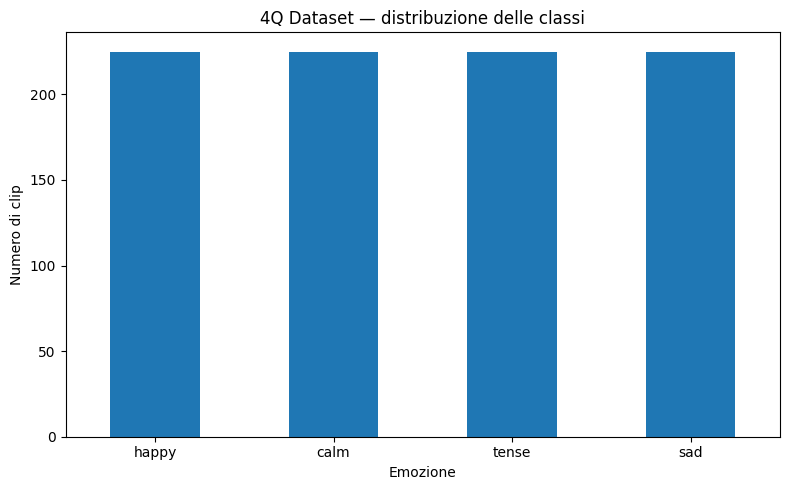

Grafico salvato in:
/content/drive/MyDrive/music_emotion_art_4q_project/results/4q_class_distribution.png


In [10]:
# 10) Visualizzazione della distribuzione delle classi

class_distribution = (
    dataset_df['label']
    .value_counts()
    .reindex(EXPECTED_LABELS, fill_value=0)
)

plt.figure(figsize=(8, 5))
class_distribution.plot(kind='bar')
plt.title('4Q Dataset — distribuzione delle classi')
plt.xlabel('Emozione')
plt.ylabel('Numero di clip')
plt.xticks(rotation=0)
plt.tight_layout()

class_distribution_path = (
    RESULTS_DIR /
    '4q_class_distribution.png'
)

plt.savefig(
    class_distribution_path,
    dpi=150,
    bbox_inches='tight',
)

plt.show()

print('Grafico salvato in:')
print(class_distribution_path)

## Suddivisione dei dati

Il dataset viene diviso una sola volta in training e test con stratificazione.

La cross-validation per il confronto dei modelli viene effettuata soltanto
sul training set. Il test set rimane separato fino alla valutazione finale.

In [11]:
# 11) Split train/test

X = dataset_df[FEATURE_COLS].copy()
y = dataset_df['label'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

print('Training set:', len(X_train))
print('Test set:', len(X_test))

print('\nDistribuzione training:')
print(
    y_train.value_counts()
    .reindex(EXPECTED_LABELS, fill_value=0)
)

print('\nDistribuzione test:')
print(
    y_test.value_counts()
    .reindex(EXPECTED_LABELS, fill_value=0)
)

Training set: 720
Test set: 180

Distribuzione training:
label
happy    180
calm     180
tense    180
sad      180
Name: count, dtype: int64

Distribuzione test:
label
happy    45
calm     45
tense    45
sad      45
Name: count, dtype: int64


## Confronto tra classificatori

La selezione del modello migliore avviene usando il Macro F1 medio in
cross-validation sul training set.

Le metriche sul test vengono calcolate per confronto, ma non vengono usate
per scegliere il modello.

In [12]:
# 12) Definizione dei modelli

models = {
    'Random Forest': Pipeline([
        (
            'imputer',
            SimpleImputer(strategy='median'),
        ),
        (
            'classifier',
            RandomForestClassifier(
                n_estimators=500,
                max_features='sqrt',
                min_samples_leaf=2,
                class_weight='balanced',
                random_state=RANDOM_STATE,
                n_jobs=-1,
            ),
        ),
    ]),

    'Extra Trees': Pipeline([
        (
            'imputer',
            SimpleImputer(strategy='median'),
        ),
        (
            'classifier',
            ExtraTreesClassifier(
                n_estimators=700,
                max_features='sqrt',
                min_samples_leaf=1,
                class_weight='balanced',
                random_state=RANDOM_STATE,
                n_jobs=-1,
            ),
        ),
    ]),

    'SVM RBF': Pipeline([
        (
            'imputer',
            SimpleImputer(strategy='median'),
        ),
        (
            'scaler',
            StandardScaler(),
        ),
        (
            'classifier',
            SVC(
                kernel='rbf',
                C=10,
                gamma='scale',
                class_weight='balanced',
                probability=True,
                random_state=RANDOM_STATE,
            ),
        ),
    ]),

    'Logistic Regression': Pipeline([
        (
            'imputer',
            SimpleImputer(strategy='median'),
        ),
        (
            'scaler',
            StandardScaler(),
        ),
        (
            'classifier',
            LogisticRegression(
                C=1.0,
                class_weight='balanced',
                max_iter=5000,
                random_state=RANDOM_STATE,
            ),
        ),
    ]),
}

cv = StratifiedKFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

print('Modelli configurati:')
for model_name in models:
    print('-', model_name)

Modelli configurati:
- Random Forest
- Extra Trees
- SVM RBF
- Logistic Regression


In [13]:
# 13) Confronto sperimentale

comparison_rows = []
trained_models = {}

for model_name, current_model in models.items():
    print('\nValutazione:', model_name)

    cv_scores = cross_val_score(
        current_model,
        X_train,
        y_train,
        cv=cv,
        scoring='f1_macro',
        n_jobs=-1,
    )

    current_model.fit(X_train, y_train)
    predictions = current_model.predict(X_test)

    comparison_rows.append({
        'model': model_name,
        'cv_macro_f1_mean': float(cv_scores.mean()),
        'cv_macro_f1_std': float(cv_scores.std()),
        'accuracy_test': float(
            accuracy_score(y_test, predictions)
        ),
        'balanced_accuracy_test': float(
            balanced_accuracy_score(
                y_test,
                predictions,
            )
        ),
        'macro_f1_test': float(
            f1_score(
                y_test,
                predictions,
                average='macro',
            )
        ),
    })

    trained_models[model_name] = current_model

comparison_df = (
    pd.DataFrame(comparison_rows)
    .sort_values(
        'cv_macro_f1_mean',
        ascending=False,
    )
    .reset_index(drop=True)
)

comparison_path = (
    RESULTS_DIR /
    '4q_model_comparison.csv'
)

comparison_df.to_csv(
    comparison_path,
    index=False,
)

display(comparison_df)

print('Confronto salvato in:')
print(comparison_path)


Valutazione: Random Forest

Valutazione: Extra Trees

Valutazione: SVM RBF

Valutazione: Logistic Regression


,model,cv_macro_f1_mean,cv_macro_f1_std,accuracy_test,balanced_accuracy_test,macro_f1_test
0,Extra Trees,0.673785,0.030449,0.683333,0.683333,0.677867
1,Random Forest,0.661902,0.030501,0.666667,0.666667,0.660857
2,SVM RBF,0.654504,0.029145,0.561111,0.561111,0.552511
3,Logistic Regression,0.616594,0.057724,0.561111,0.561111,0.554810


Confronto salvato in:
/content/drive/MyDrive/music_emotion_art_4q_project/results/4q_model_comparison.csv


In [14]:
# 14) Selezione del modello migliore

best_model_name = comparison_df.iloc[0]['model']
best_model = trained_models[best_model_name]

best_predictions = best_model.predict(X_test)

best_accuracy = accuracy_score(
    y_test,
    best_predictions,
)

best_balanced_accuracy = balanced_accuracy_score(
    y_test,
    best_predictions,
)

best_macro_f1 = f1_score(
    y_test,
    best_predictions,
    average='macro',
)

print('Modello selezionato:', best_model_name)
print(f'Accuracy test: {best_accuracy:.4f}')
print(
    f'Balanced accuracy test: '
    f'{best_balanced_accuracy:.4f}'
)
print(f'Macro F1 test: {best_macro_f1:.4f}')

print('\nClassification report:\n')

print(
    classification_report(
        y_test,
        best_predictions,
        labels=EXPECTED_LABELS,
        zero_division=0,
    )
)

Modello selezionato: Extra Trees
Accuracy test: 0.6833
Balanced accuracy test: 0.6833
Macro F1 test: 0.6779

Classification report:

              precision    recall  f1-score   support

       happy       0.65      0.76      0.70        45
        calm       0.63      0.60      0.61        45
       tense       0.83      0.89      0.86        45
         sad       0.59      0.49      0.54        45

    accuracy                           0.68       180
   macro avg       0.68      0.68      0.68       180
weighted avg       0.68      0.68      0.68       180



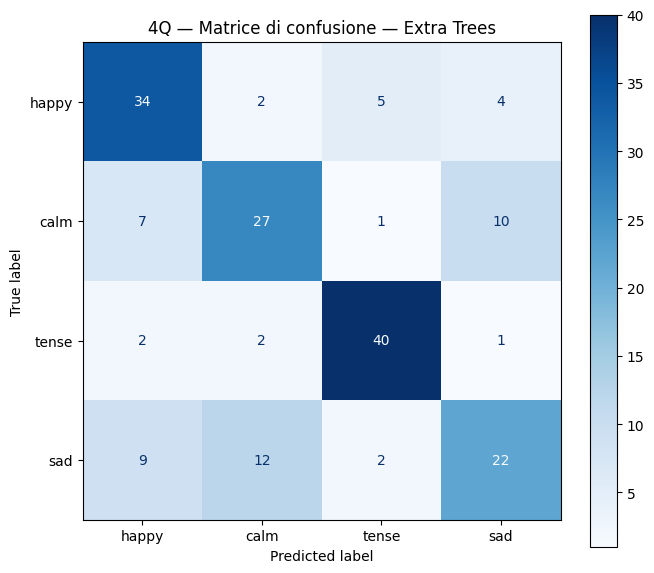

Report salvato in: /content/drive/MyDrive/music_emotion_art_4q_project/results/4q_best_model_classification_report.csv
Matrice salvata in: /content/drive/MyDrive/music_emotion_art_4q_project/results/4q_best_model_confusion_matrix.png


In [15]:
# 15) Matrice di confusione e report del modello migliore

report_dict = classification_report(
    y_test,
    best_predictions,
    labels=EXPECTED_LABELS,
    output_dict=True,
    zero_division=0,
)

report_df = pd.DataFrame(report_dict).transpose()

report_path = (
    RESULTS_DIR /
    '4q_best_model_classification_report.csv'
)

report_df.to_csv(
    report_path,
    index=True,
)

figure, axis = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    labels=EXPECTED_LABELS,
    display_labels=EXPECTED_LABELS,
    cmap='Blues',
    values_format='d',
    ax=axis,
)

axis.set_title(
    f'4Q — Matrice di confusione — {best_model_name}'
)

figure.tight_layout()

confusion_path = (
    RESULTS_DIR /
    '4q_best_model_confusion_matrix.png'
)

plt.savefig(
    confusion_path,
    dpi=150,
    bbox_inches='tight',
)

plt.show()

print('Report salvato in:', report_path)
print('Matrice salvata in:', confusion_path)

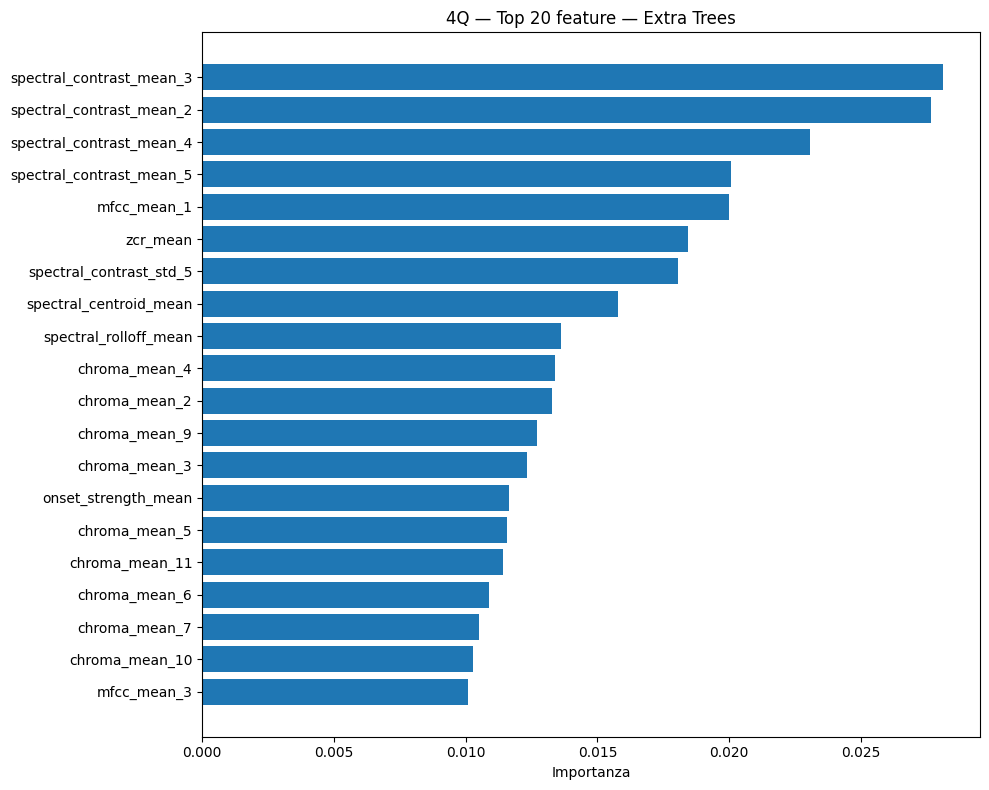

,feature,importance
0,spectral_contrast_mean_3,0.028114
1,spectral_contrast_mean_2,0.027656
2,spectral_contrast_mean_4,0.023086
3,spectral_contrast_mean_5,0.020060
4,mfcc_mean_1,0.019999
5,zcr_mean,0.018435
6,spectral_contrast_std_5,0.018064
7,spectral_centroid_mean,0.015765
8,spectral_rolloff_mean,0.013631
9,chroma_mean_4,0.013377


Importanza delle feature salvata in: /content/drive/MyDrive/music_emotion_art_4q_project/results/4q_best_model_feature_importance.csv


In [16]:
# 16) Importanza delle feature per i modelli ad alberi

classifier = best_model.named_steps['classifier']

if hasattr(classifier, 'feature_importances_'):
    importance_df = (
        pd.DataFrame({
            'feature': FEATURE_COLS,
            'importance': classifier.feature_importances_,
        })
        .sort_values(
            'importance',
            ascending=False,
        )
        .reset_index(drop=True)
    )

    importance_path = (
        RESULTS_DIR /
        '4q_best_model_feature_importance.csv'
    )

    importance_df.to_csv(
        importance_path,
        index=False,
    )

    top_features = (
        importance_df
        .head(20)
        .sort_values('importance')
    )

    plt.figure(figsize=(10, 8))
    plt.barh(
        top_features['feature'],
        top_features['importance'],
    )
    plt.xlabel('Importanza')
    plt.title(
        f'4Q — Top 20 feature — {best_model_name}'
    )
    plt.tight_layout()

    importance_plot_path = (
        RESULTS_DIR /
        '4q_best_model_feature_importance_top20.png'
    )

    plt.savefig(
        importance_plot_path,
        dpi=150,
        bbox_inches='tight',
    )

    plt.show()

    display(importance_df.head(20))

    print(
        'Importanza delle feature salvata in:',
        importance_path,
    )

else:
    print(
        'Il modello migliore non espone '
        'feature_importances_.'
    )

In [17]:
# 17) Salvataggio del modello migliore e delle metriche

feature_reference = {
    'tempo_median': float(
        dataset_df['tempo'].median()
    ),
    'energy_median': float(
        dataset_df['energy_mean'].median()
    ),
    'spectral_centroid_median': float(
        dataset_df[
            'spectral_centroid_mean'
        ].median()
    ),
}

model_bundle = {
    'model': best_model,
    'model_name': best_model_name,
    'feature_cols': FEATURE_COLS,
    'expected_labels': EXPECTED_LABELS,
    'feature_reference': feature_reference,
    'max_duration': MAX_DURATION,
    'random_state': RANDOM_STATE,
    'quadrant_to_label': QUADRANT_TO_LABEL,
}

model_path = (
    MODELS_DIR /
    '4q_best_emotion_classifier_bundle.joblib'
)

joblib.dump(
    model_bundle,
    model_path,
)

best_cv_row = comparison_df.iloc[0]

metrics = {
    'dataset': '4Q Audio Emotion Dataset',
    'samples': int(len(dataset_df)),
    'features': int(len(FEATURE_COLS)),
    'best_model': best_model_name,
    'cv_macro_f1_mean': float(
        best_cv_row['cv_macro_f1_mean']
    ),
    'cv_macro_f1_std': float(
        best_cv_row['cv_macro_f1_std']
    ),
    'accuracy_test': float(best_accuracy),
    'balanced_accuracy_test': float(
        best_balanced_accuracy
    ),
    'macro_f1_test': float(best_macro_f1),
    'max_duration': int(MAX_DURATION),
    'test_size': float(TEST_SIZE),
    'random_state': int(RANDOM_STATE),
}

metrics_path = (
    RESULTS_DIR /
    '4q_evaluation_metrics.json'
)

with open(
    metrics_path,
    'w',
    encoding='utf-8',
) as file:
    json.dump(
        metrics,
        file,
        indent=2,
        ensure_ascii=False,
    )

print('Modello salvato in:')
print(model_path)

print('\nMetriche salvate in:')
print(metrics_path)

Modello salvato in:
/content/drive/MyDrive/music_emotion_art_4q_project/models/4q_best_emotion_classifier_bundle.joblib

Metriche salvate in:
/content/drive/MyDrive/music_emotion_art_4q_project/results/4q_evaluation_metrics.json


## Confronto opzionale con i risultati DEAM

La cella seguente cerca il file delle metriche prodotto dal notebook DEAM.

Il confronto è significativo perché entrambe le versioni utilizzano:

- quattro emozioni;
- Macro F1;
- balanced accuracy;
- split train/test;
- classificatori basati sulle feature audio.

Rimangono comunque dataset differenti, con annotazioni e selezione dei brani differenti.

In [18]:
# 18) Confronto con DEAM, se le metriche sono presenti su Drive

deam_metrics_path = Path(
    '/content/drive/MyDrive/'
    'music_emotion_art_project/'
    'results/'
    'evaluation_metrics.json'
)

comparison_dataset_rows = [{
    'dataset': '4Q',
    'model': best_model_name,
    'accuracy_test': best_accuracy,
    'balanced_accuracy_test': best_balanced_accuracy,
    'macro_f1_test': best_macro_f1,
    'cv_macro_f1_mean': float(
        comparison_df.iloc[0][
            'cv_macro_f1_mean'
        ]
    ),
}]

if deam_metrics_path.exists():
    with open(
        deam_metrics_path,
        'r',
        encoding='utf-8',
    ) as file:
        deam_metrics = json.load(file)

    comparison_dataset_rows.append({
        'dataset': 'DEAM',
        'model': (
            deam_metrics.get(
                'best_model',
                'Random Forest',
            )
        ),
        'accuracy_test': deam_metrics.get(
            'accuracy_test'
        ),
        'balanced_accuracy_test': (
            deam_metrics.get(
                'balanced_accuracy_test'
            )
        ),
        'macro_f1_test': deam_metrics.get(
            'macro_f1_test'
        ),
        'cv_macro_f1_mean': (
            deam_metrics.get(
                'cv_macro_f1_mean'
            )
        ),
    })

dataset_comparison_df = pd.DataFrame(
    comparison_dataset_rows
)

dataset_comparison_path = (
    RESULTS_DIR /
    '4q_vs_deam_comparison.csv'
)

dataset_comparison_df.to_csv(
    dataset_comparison_path,
    index=False,
)

display(dataset_comparison_df)

print('Confronto salvato in:')
print(dataset_comparison_path)

if not deam_metrics_path.exists():
    print(
        '\nMetriche DEAM non trovate. '
        'È stata salvata soltanto la riga 4Q.'
    )

,dataset,model,accuracy_test,balanced_accuracy_test,macro_f1_test,cv_macro_f1_mean
0,4Q,Extra Trees,0.683333,0.683333,0.677867,0.673785
1,DEAM,Random Forest,0.483696,0.483696,0.458368,0.469708


Confronto salvato in:
/content/drive/MyDrive/music_emotion_art_4q_project/results/4q_vs_deam_comparison.csv


## Generazione delle immagini: modalità astratta o figurativa

La classificazione dell'emozione e l'estrazione delle feature restano invariate.

La variabile `VISUAL_MODE` permette di scegliere:

- `abstract`: composizioni non figurative;
- `figurative`: scene riconoscibili con una figura umana distante e un ambiente coerente con l'emozione.

Per un confronto corretto tra le due modalità è consigliato utilizzare lo stesso file audio e lo stesso seed.


In [25]:
# 19) Costruzione del prompt artistico

# Scegli:
# 'abstract'   -> immagine astratta
# 'figurative' -> immagine figurativa con soggetti riconoscibili
VISUAL_MODE = 'figurative'


ABSTRACT_EMOTION_STYLES = {
    'happy': (
        'bright yellow, light blue and pastel colors, '
        'rounded shapes, joyful movement, '
        'open composition, warm light'
    ),
    'calm': (
        'soft green, beige and pale blue colors, '
        'smooth waves, minimal composition, '
        'relaxed atmosphere'
    ),
    'tense': (
        'dark red and black colors, '
        'fragmented sharp shapes, '
        'chaotic composition, dramatic shadows, '
        'high contrast'
    ),
    'sad': (
        'deep blue, violet and grey colors, '
        'soft blurred shapes, slow movement, '
        'melancholic atmosphere, low contrast'
    ),
}


# Qui non vengono imposti luoghi o soggetti specifici.
# Viene indicata soltanto l'emozione da rappresentare.
FIGURATIVE_EMOTION_STYLES = {
    'happy': (
        'a recognizable figurative scene expressing joy, '
        'optimism, vitality and emotional openness'
    ),
    'calm': (
        'a recognizable figurative scene expressing calm, '
        'serenity, balance and emotional quietness'
    ),
    'tense': (
        'a recognizable figurative scene expressing tension, '
        'instability, urgency and emotional intensity'
    ),
    'sad': (
        'a recognizable figurative scene expressing sadness, '
        'solitude, melancholy and introspection'
    ),
}


NEGATIVE_PROMPTS = {
    'abstract': (
        'text, letters, words, watermark, signature, '
        'realistic faces, people, recognizable objects, '
        'photorealistic scene, logo'
    ),

    'figurative': (
        'text, letters, words, watermark, signature, logo, '
        'bad anatomy, deformed body, extra limbs, '
        'extra fingers, malformed hands, duplicated subjects, '
        'distorted face, blurry, low quality'
    ),
}


if VISUAL_MODE not in {'abstract', 'figurative'}:
    raise ValueError(
        "VISUAL_MODE deve essere 'abstract' oppure 'figurative'."
    )


NEGATIVE_PROMPT = NEGATIVE_PROMPTS[VISUAL_MODE]


def build_prompt(emotion, features, references):

    if emotion not in ABSTRACT_EMOTION_STYLES:
        raise ValueError(
            f'Emozione non supportata: {emotion}'
        )

    # =========================================================
    # MODALITÀ ASTRATTA
    # =========================================================
    if VISUAL_MODE == 'abstract':

        descriptors = [
            'abstract digital artwork',
            ABSTRACT_EMOTION_STYLES[emotion],
            'visual interpretation of musical emotion',
            'non figurative composition',
        ]

        # Tempo musicale
        if (
            features['tempo']
            >= references['tempo_median']
        ):
            descriptors.append(
                'rapid visual rhythm and dynamic composition'
            )
        else:
            descriptors.append(
                'slow visual rhythm and fluid composition'
            )

        # Energia
        if (
            features['energy_mean']
            >= references['energy_median']
        ):
            descriptors.append(
                'vivid colors and energetic brush strokes'
            )
        else:
            descriptors.append(
                'delicate colors and soft transitions'
            )

        # Centroide spettrale
        if (
            features['spectral_centroid_mean']
            >= references['spectral_centroid_median']
        ):
            descriptors.append(
                'luminous highlights and airy textures'
            )
        else:
            descriptors.append(
                'deep tones and dense textures'
            )

        # Modalità maggiore/minore
        if int(features['mode_binary']) == 1:
            descriptors.append(
                'harmonious and expansive visual balance'
            )
        else:
            descriptors.append(
                'introspective and suspended visual balance'
            )

    # =========================================================
    # MODALITÀ FIGURATIVA
    # =========================================================
    else:

        descriptors = [
            'figurative cinematic digital artwork',
            FIGURATIVE_EMOTION_STYLES[emotion],
            'recognizable subjects and environment',
            'creative and original visual interpretation',
            'the scene must communicate the musical emotion',
            'detailed coherent composition',
            'cinematic atmosphere',
        ]

        # Tempo musicale:
        # non stabilisce il soggetto, ma solo il movimento visivo.
        if (
            features['tempo']
            >= references['tempo_median']
        ):
            descriptors.append(
                'dynamic scene, visible movement, '
                'energetic perspective and visual rhythm'
            )
        else:
            descriptors.append(
                'still scene, gentle movement, '
                'balanced and contemplative composition'
            )

        # Energia:
        # controlla intensità, luce e saturazione.
        if (
            features['energy_mean']
            >= references['energy_median']
        ):
            descriptors.append(
                'strong cinematic lighting, '
                'intense atmosphere and saturated colors'
            )
        else:
            descriptors.append(
                'soft diffused lighting, '
                'delicate atmosphere and muted colors'
            )

        # Centroide spettrale:
        # influenza luminosità e densità dell'ambiente.
        if (
            features['spectral_centroid_mean']
            >= references['spectral_centroid_median']
        ):
            descriptors.append(
                'bright atmosphere, crisp highlights, '
                'clear details and airy environment'
            )
        else:
            descriptors.append(
                'deep shadows, darker tones, '
                'dense atmosphere and soft details'
            )

        # Modalità maggiore/minore:
        # influenza il carattere generale della scena.
        if int(features['mode_binary']) == 1:
            descriptors.append(
                'open, harmonious and hopeful visual balance'
            )
        else:
            descriptors.append(
                'introspective, suspended and emotionally '
                'complex visual balance'
            )

    return ', '.join(descriptors)

In [27]:
# 20) Caricamento di Stable Diffusion

import torch
from diffusers import StableDiffusionPipeline

if not torch.cuda.is_available():
    raise RuntimeError(
        'GPU non disponibile. In Colab seleziona '
        'Runtime → Change runtime type → GPU.'
    )

DEVICE = 'cuda'
DIFFUSION_MODEL_ID = (
    'stable-diffusion-v1-5/'
    'stable-diffusion-v1-5'
)
GENERATION_SEED = 42

pipe = StableDiffusionPipeline.from_pretrained(
    DIFFUSION_MODEL_ID,
    torch_dtype=torch.float16,
    use_safetensors=True,
)

pipe = pipe.to(DEVICE)
pipe.enable_attention_slicing()

print('Stable Diffusion caricato correttamente.')
print('Modello:', DIFFUSION_MODEL_ID)
print('Device:', DEVICE)

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Stable Diffusion caricato correttamente.
Modello: stable-diffusion-v1-5/stable-diffusion-v1-5
Device: cuda


In [28]:
# 21) Funzioni finali: audio -> emozione -> immagine

def clean_filename(filename):
    name = Path(filename).stem

    return re.sub(
        r'[^a-zA-Z0-9_-]+',
        '_',
        name,
    ).strip('_')


def classify_emotion_ml(audio_path):
    features = extract_audio_features(
        audio_path,
        max_duration=model_bundle[
            'max_duration'
        ],
    )

    feature_row = pd.DataFrame(
        [features],
        columns=model_bundle['feature_cols'],
    )

    predicted_emotion = (
        model_bundle['model']
        .predict(feature_row)[0]
    )

    probabilities = (
        model_bundle['model']
        .predict_proba(feature_row)[0]
    )

    classifier = (
        model_bundle['model']
        .named_steps['classifier']
    )

    classes = classifier.classes_

    probability_map = {
        class_name: float(probability)
        for class_name, probability
        in zip(classes, probabilities)
    }

    return (
        predicted_emotion,
        probability_map,
        features,
    )


def generate_art_from_audio(
    audio_path,
    seed=GENERATION_SEED,
):
    (
        emotion,
        probabilities,
        features,
    ) = classify_emotion_ml(audio_path)

    prompt = build_prompt(
        emotion,
        features,
        model_bundle['feature_reference'],
    )

    generator = (
        torch.Generator(device=DEVICE)
        .manual_seed(seed)
    )

    image = pipe(
        prompt=prompt,
        negative_prompt=NEGATIVE_PROMPT,
        num_inference_steps=30,
        guidance_scale=7.5,
        width=512,
        height=512,
        generator=generator,
    ).images[0]

    output_name = (
        f'{clean_filename(audio_path)}_'
        f'{emotion}_{VISUAL_MODE}_seed{seed}.png'
    )

    image_path = (
        GENERATED_DIR /
        output_name
    )

    image.save(image_path)

    result = {
        'audio_file': Path(audio_path).name,
        'predicted_emotion': emotion,
        'prediction_confidence': float(
            max(probabilities.values())
        ),
        'class_probabilities': json.dumps(
            probabilities,
            ensure_ascii=False,
        ),
        'tempo': float(features['tempo']),
        'energy': float(
            features['energy_mean']
        ),
        'spectral_centroid': float(
            features[
                'spectral_centroid_mean'
            ]
        ),
        'mode_binary': int(
            features['mode_binary']
        ),
        'classifier': model_bundle[
            'model_name'
        ],
        'visual_mode': VISUAL_MODE,
        'prompt': prompt,
        'negative_prompt': NEGATIVE_PROMPT,
        'diffusion_model': DIFFUSION_MODEL_ID,
        'seed': int(seed),
        'image_path': str(image_path),
    }

    return result, image


In [29]:
# Valutazione CLIP delle immagini generate

from transformers import CLIPModel, CLIPProcessor
import torch.nn.functional as F

CLIP_MODEL_ID = "openai/clip-vit-base-patch32"

clip_model = CLIPModel.from_pretrained(CLIP_MODEL_ID).to(DEVICE)
clip_processor = CLIPProcessor.from_pretrained(CLIP_MODEL_ID)
clip_model.eval()

descrizioni_emozioni = {
    "happy": "happiness and joy",
    "calm": "calm and serenity",
    "tense": "tension and anxiety",
    "sad": "sadness and melancholy",
}

tipo_arte = (
    "an abstract"
    if VISUAL_MODE == "abstract"
    else "a figurative"
)

prompt_emozioni = [
    f"{tipo_arte} artwork expressing {descrizioni_emozioni[emozione]}"
    for emozione in EXPECTED_LABELS
]

def valuta_immagine(image, emozione_attesa):
    inputs = clip_processor(
        text=prompt_emozioni,
        images=image,
        return_tensors="pt",
        padding=True
    ).to(DEVICE)

    with torch.inference_mode():
        output = clip_model(**inputs)

    image_features = F.normalize(output.image_embeds, dim=-1)
    text_features = F.normalize(output.text_embeds, dim=-1)
    similarita = (image_features @ text_features.T)[0]

    indice_migliore = similarita.argmax().item()

    return {
        "clip_emozione_abbinata": EXPECTED_LABELS[indice_migliore],
        "clip_similarity_emozione_predetta": float(
            similarita[EXPECTED_LABELS.index(emozione_attesa)].item()
        )
    }

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

## Demo su un nuovo brano o più brani

Il file caricato viene copiato anche su Google Drive nella cartella
`uploaded_audio`, quindi rimane disponibile dopo la chiusura del runtime.

Saving alec_koff-carnaval-484622.mp3 to alec_koff-carnaval-484622 (1).mp3
Saving artmylife-powerful-dramatic-trailer-514242.mp3 to artmylife-powerful-dramatic-trailer-514242 (1).mp3
Saving mickeyscat-moment-of-peace-mickeyscat-554494.mp3 to mickeyscat-moment-of-peace-mickeyscat-554494 (1).mp3
Saving sigmamusicart-no-copyright-music-537751.mp3 to sigmamusicart-no-copyright-music-537751 (1).mp3

=== Brano 1/4: alec_koff-carnaval-484622 (1).mp3 ===


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (88 > 77). Running this sequence through the model will result in indexing errors
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['and airy environment , introspective , suspended and emotionally complex visual balance']


  0%|          | 0/30 [00:00<?, ?it/s]

Emozione predetta: tense
Emozione abbinata da CLIP: happy
Similarità CLIP con l'emozione attesa: 0.227


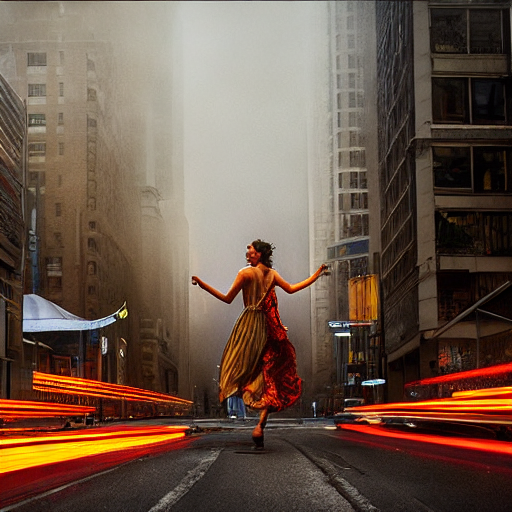


=== Brano 2/4: artmylife-powerful-dramatic-trailer-514242 (1).mp3 ===


The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['dense atmosphere and soft details , introspective , suspended and emotionally complex visual balance']


  0%|          | 0/30 [00:00<?, ?it/s]

Emozione predetta: calm
Emozione abbinata da CLIP: calm
Similarità CLIP con l'emozione attesa: 0.281


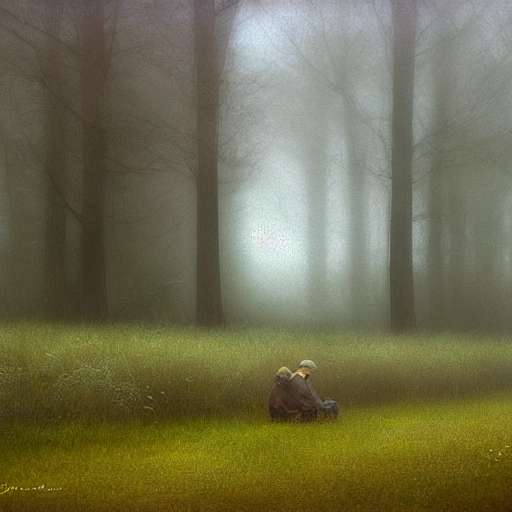


=== Brano 3/4: mickeyscat-moment-of-peace-mickeyscat-554494 (1).mp3 ===


The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['dense atmosphere and soft details , open , harmonious and hopeful visual balance']


  0%|          | 0/30 [00:00<?, ?it/s]

Emozione predetta: calm
Emozione abbinata da CLIP: calm
Similarità CLIP con l'emozione attesa: 0.289


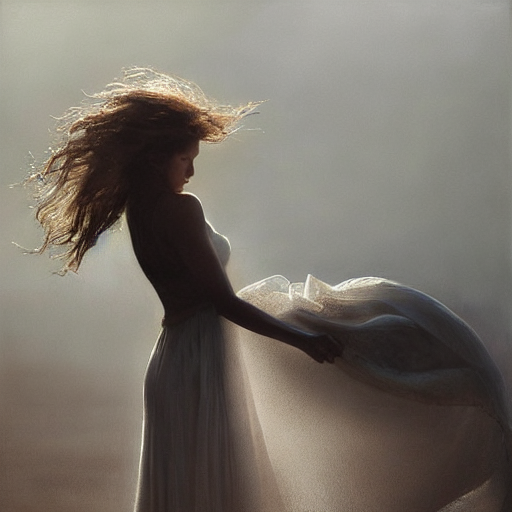


=== Brano 4/4: sigmamusicart-no-copyright-music-537751 (1).mp3 ===


The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['details and airy environment , open , harmonious and hopeful visual balance']


  0%|          | 0/30 [00:00<?, ?it/s]

Emozione predetta: happy
Emozione abbinata da CLIP: happy
Similarità CLIP con l'emozione attesa: 0.294


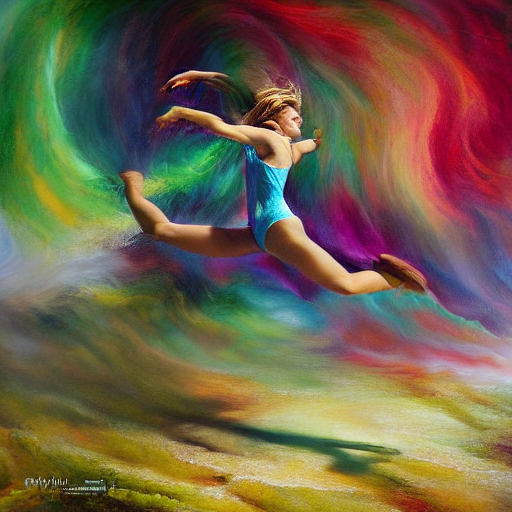


Risultati salvati in: /content/drive/MyDrive/music_emotion_art_4q_project/results/4q_uploaded_audio_results.csv


,audio_file,predicted_emotion,prediction_confidence,class_probabilities,tempo,energy,spectral_centroid,mode_binary,classifier,visual_mode,prompt,negative_prompt,diffusion_model,seed,image_path,clip_emozione_abbinata,clip_similarity_emozione_attesa
0,alec_koff-carnaval-484622 (1).mp3,tense,0.818571,"{""calm"": 0.02142857142857143, ""happy"": 0.14571...",117.453835,0.240902,2666.717660,0,Extra Trees,figurative,"figurative cinematic digital artwork, a recogn...","text, letters, words, watermark, signature, lo...",stable-diffusion-v1-5/stable-diffusion-v1-5,42,/content/drive/MyDrive/music_emotion_art_4q_pr...,happy,0.226914
1,artmylife-powerful-dramatic-trailer-514242 (1)...,calm,0.578571,"{""calm"": 0.5785714285714286, ""happy"": 0.062857...",112.347147,0.073366,600.022486,0,Extra Trees,figurative,"figurative cinematic digital artwork, a recogn...","text, letters, words, watermark, signature, lo...",stable-diffusion-v1-5/stable-diffusion-v1-5,43,/content/drive/MyDrive/music_emotion_art_4q_pr...,calm,0.281217
2,mickeyscat-moment-of-peace-mickeyscat-554494 (...,calm,0.668571,"{""calm"": 0.6685714285714286, ""happy"": 0.075714...",161.499023,0.047006,853.176240,1,Extra Trees,figurative,"figurative cinematic digital artwork, a recogn...","text, letters, words, watermark, signature, lo...",stable-diffusion-v1-5/stable-diffusion-v1-5,44,/content/drive/MyDrive/music_emotion_art_4q_pr...,calm,0.288781
3,sigmamusicart-no-copyright-music-537751 (1).mp3,happy,0.320000,"{""calm"": 0.29285714285714287, ""happy"": 0.32, ""...",151.999081,0.256234,2209.085971,1,Extra Trees,figurative,"figurative cinematic digital artwork, a recogn...","text, letters, words, watermark, signature, lo...",stable-diffusion-v1-5/stable-diffusion-v1-5,45,/content/drive/MyDrive/music_emotion_art_4q_pr...,happy,0.293863


In [30]:
# 22) Upload di uno o più brani, generazione e valutazione CLIP

from google.colab import files

uploaded = files.upload()

audio_files = [
    filename
    for filename in uploaded.keys()
    if Path(filename).suffix.lower() in AUDIO_EXTENSIONS
]

if not audio_files:
    raise ValueError("Non è stato caricato nessun audio supportato.")

results = []

for index, audio_file in enumerate(audio_files):
    print(f"\n=== Brano {index + 1}/{len(audio_files)}: {audio_file} ===")

    permanent_path = UPLOADED_AUDIO_DIR / Path(audio_file).name
    shutil.copy2(audio_file, permanent_path)

    result_i, image_i = generate_art_from_audio(
        permanent_path,
        seed=GENERATION_SEED + index
    )

    # Valuta con CLIP questa immagine e aggiunge i risultati
    # alla riga relativa a questo brano
    clip_metrics_i = valuta_immagine(
        image_i,
        result_i["predicted_emotion"]
    )
    result_i.update(clip_metrics_i)

    results.append(result_i)

    print("Emozione predetta:", result_i["predicted_emotion"])
    print("Emozione abbinata da CLIP:", result_i["clip_emozione_abbinata"])
    print(
        "Similarità CLIP con l'emozione predetta:",
        round(result_i["clip_similarity_emozione_predetta"], 3)
    )

    display(image_i)

# Un'unica riga del CSV per ciascun audio
results_df = pd.DataFrame(results)
results_path = RESULTS_DIR / "4q_uploaded_audio_results.csv"
results_df.to_csv(results_path, index=False)

print("\nRisultati salvati in:", results_path)
display(results_df)